## This notebook crops the Petri-dish region for all images, selecting a random subset from all years and crop the Petri-dish region and visualize a few.


val_Jason_234041_im2.png
  Original shape: (3006, 4112)
  Cropped shape : (2802, 2802)

val_Karna_232922_im1.png
  Original shape: (3006, 4202)
  Cropped shape : (2779, 2779)

val_Jason_234301_im4.png
  Original shape: (3006, 4112)
  Cropped shape : (2803, 2803)

051_43-18-ROOT1-2023-08-08_pvd_OD0001_col-0_01-Fish Eye Corrected.png
  Original shape: (3006, 4202)
  Cropped shape : (2834, 2834)

val_Myrthe_236578_im1.png
  Original shape: (3006, 4202)
  Cropped shape : (2778, 2778)

train_Elavendan_236535_im5.png
  Original shape: (3006, 4202)
  Cropped shape : (2779, 2779)


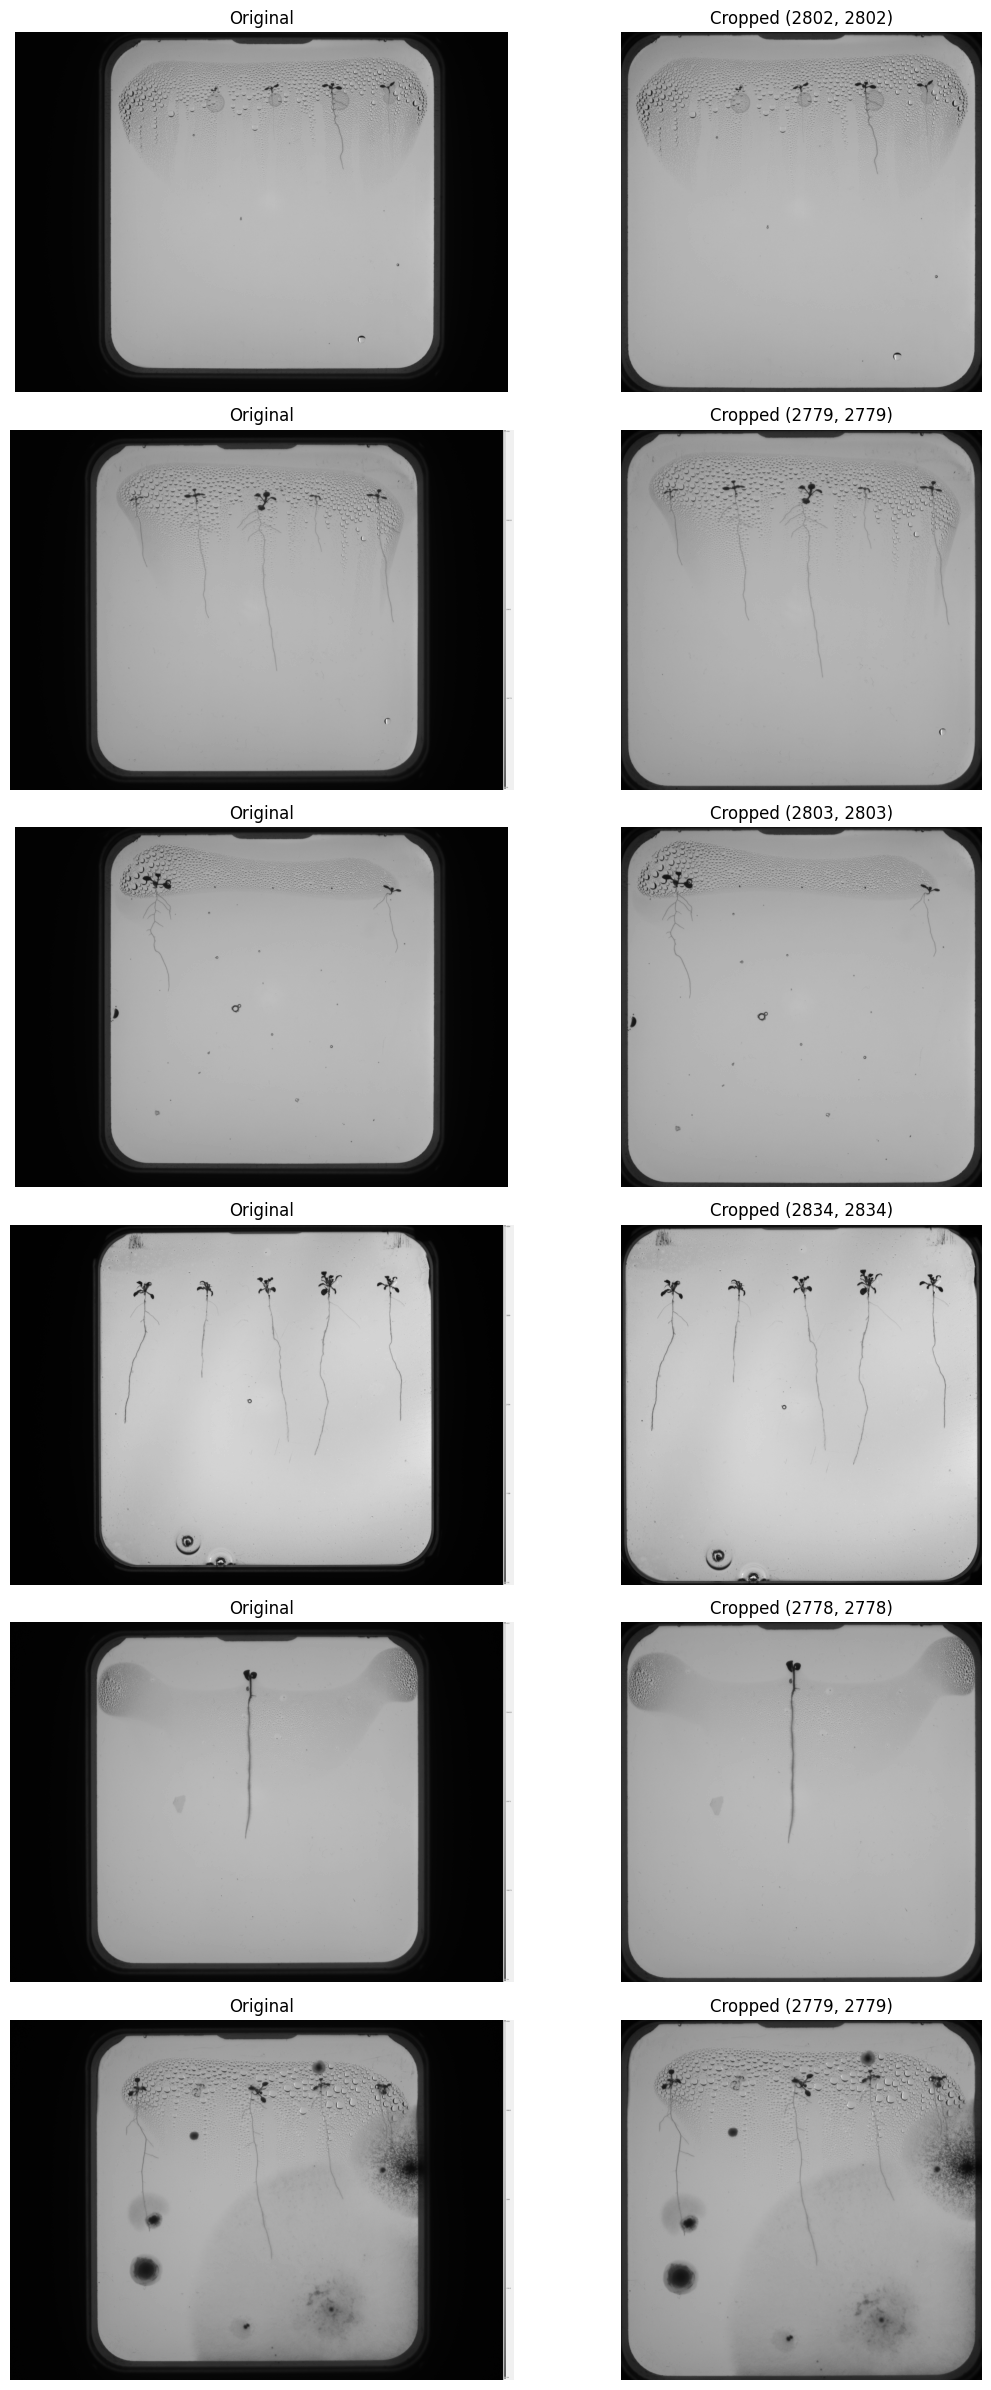

In [1]:
"""
Task 2: Petri Dish Detection and Extraction

This notebook finds and crops the Petri dish from plant images
using traditional computer vision methods (no ML or DL).

Works for datasets:
- Y2B_23
- Y2B_24
- Y2B_25
"""

import os
import cv2
import matplotlib.pyplot as plt
import random
from skimage.morphology import remove_small_objects
from skimage.measure import label, regionprops

# Parameters
MARGIN_PX = 30

# IMAGE FOLDER
IMAGE_FOLDER = r"D:\myfile\Y2-B\Task 2\All_Images"


def crop_petri_dish(img):
    """
    Detects and crops the Petri dish region from a single grayscale image.

    Method:
    - Gaussian smoothing
    - Otsu thresholding
    - Largest bright connected component selection
    - Fixed margin added around the detected dish
    - Convert bbox to a SQUARE crop by expanding the shorter dimension
    - Shift square crop in-bounds (NO padding)
    - Final output is always square (N, N), where N may vary per image

    If detection fails, a centered square crop is used.
    """
    H, W = img.shape

    # Reduce noise before thresholding
    blur = cv2.GaussianBlur(img, (9, 9), 0)

    # Convert to binary image using Otsu's method
    _, thresh = cv2.threshold(
        blur, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Keep only bright regions and remove small objects
    bright = (thresh == 255)
    bright = remove_small_objects(bright, min_size=5000)

    # Label connected components
    labeled = label(bright)
    regions = regionprops(labeled)

    if not regions:
        # Fallback: centered square crop
        size = min(H, W)
        sy = (H - size) // 2
        sx = (W - size) // 2
        cropped = img[sy:sy+size, sx:sx+size]
        return cropped, ("fallback",)

    # Select the largest region as the Petri dish
    r = max(regions, key=lambda rr: rr.area)
    minr, minc, maxr, maxc = r.bbox

    # Add margin and clamp to image boundaries
    minr2 = max(minr - MARGIN_PX, 0)
    minc2 = max(minc - MARGIN_PX, 0)
    maxr2 = min(maxr + MARGIN_PX, H)
    maxc2 = min(maxc + MARGIN_PX, W)

    # ---- Force square crop (variable size, no padding) ----
    box_h = maxr2 - minr2
    box_w = maxc2 - minc2
    side = int(max(box_h, box_w))  # square side length

    cy = (minr2 + maxr2) // 2
    cx = (minc2 + maxc2) // 2
    half = side // 2

    y1 = cy - half
    x1 = cx - half
    y2 = y1 + side
    x2 = x1 + side

    # Shift square window to stay in-bounds (NO padding)
    if y1 < 0:
        y2 -= y1
        y1 = 0
    if x1 < 0:
        x2 -= x1
        x1 = 0
    if y2 > H:
        y1 -= (y2 - H)
        y2 = H
    if x2 > W:
        x1 -= (x2 - W)
        x2 = W

    # Final clamp
    y1 = max(int(y1), 0)
    x1 = max(int(x1), 0)
    y2 = min(int(y2), H)
    x2 = min(int(x2), W)

    cropped = img[y1:y2, x1:x2]

    # Safety: enforce square (handles rare 1px rounding issues)
    s = min(cropped.shape[0], cropped.shape[1])
    cropped = cropped[:s, :s]

    return cropped, (minr, minc, maxr, maxc, y1, x1, y2, x2, "square")


def show_random_crops(image_folder, n_samples=6):
    """
    Randomly selects images from the folder, applies Petri dish cropping,
    and displays the original and cropped results.
    """
    images = [
        f for f in os.listdir(image_folder)
        if f.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff"))
    ]

    if not images:
        raise FileNotFoundError(f"No images found in: {image_folder}")

    samples = random.sample(images, min(n_samples, len(images)))
    plt.figure(figsize=(12, 4 * len(samples)))

    for i, fname in enumerate(samples):
        img_path = os.path.join(image_folder, fname)
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

        if img is None:
            print(f"Skipping unreadable image: {fname}")
            continue

        cropped, bbox_info = crop_petri_dish(img)

        print(f"\n{fname}")
        print(f"  Original shape: {img.shape}")
        print(f"  Cropped shape : {cropped.shape}")

        if bbox_info[0] == "fallback":
            print("  Result: fallback center crop")

        # Display original image
        plt.subplot(len(samples), 2, 2*i + 1)
        plt.imshow(img, cmap="gray")
        plt.title("Original")
        plt.axis("off")

        # Display cropped image
        plt.subplot(len(samples), 2, 2*i + 2)
        plt.imshow(cropped, cmap="gray")
        plt.title(f"Cropped {cropped.shape}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


# RUN TASK 2
show_random_crops(IMAGE_FOLDER, n_samples=6)
